# Desafio 02 — Investigue uma pergunta com Python
## Análise Exploratória: E-commerce Sales Performance

**Equipe:** Mário Henrique Bezerra Rocha

## 1. A base escolhida
Escolhemos a base "E-commerce Orders and Sales Performance Dataset". Ela contém 3.500 pedidos de um e-commerce, com informações de data, produto, categoria, região, quantidade, valor de venda e lucro.

## 2. As perguntas
1. **Quais categorias de produtos geram mais receita e mais lucro?**
2. **Existe relação entre a quantidade vendida e o lucro por pedido?**
3. **Produtos da categoria "Electronics" têm um lucro médio por pedido maior do que "Accessories"?** (Comparação de dois grupos que será respondida com um teste de hipótese).

In [19]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

# Para ler do Google Drive, precisamos montá-lo primeiro:
from google.colab import drive
drive.mount('/content/drive')

# AJUSTE O CAMINHO ABAIXO com a pasta correta onde seu arquivo está no Drive
# Por exemplo: '/content/drive/MyDrive/Seu_Diretorio/ecommerce_sales_data_original.csv'
# Se você já tiver a base tratada no Drive, pode apontar diretamente para ela!
caminho_arquivo = '/content/drive/MyDrive/ecommerce_sales_data_original.csv'

# Carregando a base
df = pd.read_csv(caminho_arquivo)

# Convertendo datas e criando novas colunas
df['Order Date'] = pd.to_datetime(df['Order Date'])
df['Year'] = df['Order Date'].dt.year
df['Month'] = df['Order Date'].dt.month_name()
df['Day_of_Week'] = df['Order Date'].dt.day_name()
df['Quarter'] = df['Order Date'].dt.quarter
df['Unit_Price'] = df['Sales'] / df['Quantity']
df['Profit_Margin_%'] = (df['Profit'] / df['Sales']) * 100

# Salvando a base tratada
df.to_csv('ecommerce_sales_data_tratado.csv', index=False)

print("Base tratada com sucesso!")
df.head()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Base tratada com sucesso!


,Order Date,Product Name,Category,Region,Quantity,Sales,Profit,Year,Month,Day_of_Week,Quarter,Unit_Price,Profit_Margin_%
0,2024-12-31,Printer,Office,North,4,3640,348.93,2024,December,Tuesday,4,910.0,9.585989
1,2022-11-27,Mouse,Accessories,East,7,1197,106.53,2022,November,Sunday,4,171.0,8.899749
2,2022-05-11,Tablet,Electronics,South,5,5865,502.73,2022,May,Wednesday,2,1173.0,8.571697
3,2024-03-16,Mouse,Accessories,South,2,786,202.87,2024,March,Saturday,1,393.0,25.810433
4,2022-09-10,Mouse,Accessories,West,1,509,103.28,2022,September,Saturday,3,509.0,20.290766


## 3. Análise

### Pergunta 1: Quais categorias geram mais receita e lucro?
Vamos agrupar os dados por categoria para comparar.

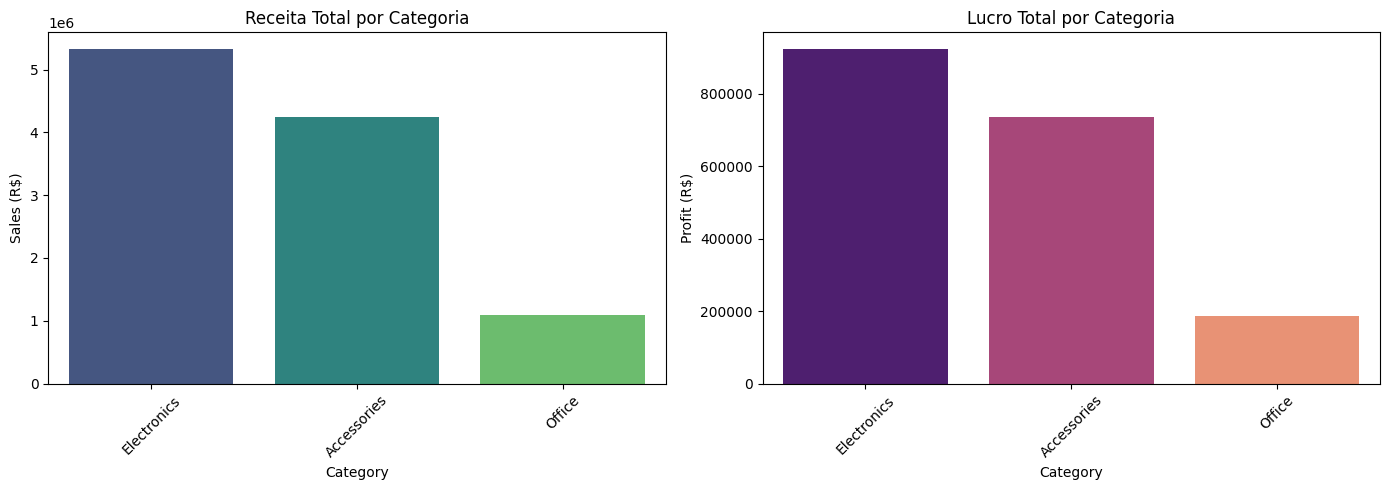

In [20]:
# Agrupando os dados
categoria_stats = df.groupby('Category')[['Sales', 'Profit']].sum().reset_index()
categoria_stats = categoria_stats.sort_values(by='Sales', ascending=False)

# Criando os gráficos
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(data=categoria_stats, x='Category', y='Sales', ax=ax[0], palette='viridis')
ax[0].set_title('Receita Total por Categoria')
ax[0].set_ylabel('Sales (R$)')
ax[0].tick_params(axis='x', rotation=45)

sns.barplot(data=categoria_stats, x='Category', y='Profit', ax=ax[1], palette='magma')
ax[1].set_title('Lucro Total por Categoria')
ax[1].set_ylabel('Profit (R$)')
ax[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

### Pergunta 2: Existe relação entre quantidade vendida e lucro?
Vamos usar um gráfico de dispersão para visualizar.

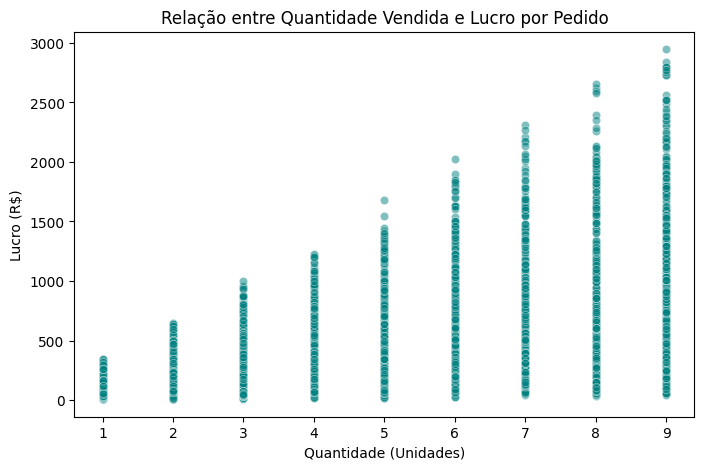

Correlação: 0.56


In [21]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='Quantity', y='Profit', alpha=0.5, color='teal')
plt.title('Relação entre Quantidade Vendida e Lucro por Pedido')
plt.xlabel('Quantidade (Unidades)')
plt.ylabel('Lucro (R$)')
plt.show()

correlacao = df[['Quantity', 'Profit']].corr().iloc[0, 1]
print(f"Correlação: {correlacao:.2f}")

### Pergunta 3: Teste de Hipótese (Electronics vs Accessories)
- **Hipótese Nula (H0):** O lucro médio de Electronics é igual ao de Accessories.
- **Hipótese Alternativa (H1):** O lucro médio de Electronics é diferente (maior).

Vamos aplicar o teste t de Student.

Média de Lucro (Electronics): R$ 529.96
Média de Lucro (Accessories): R$ 525.40
Valor-p: 0.8016

Conclusão: NÃO REJEITAMOS a hipótese nula. Não há diferença significativa.


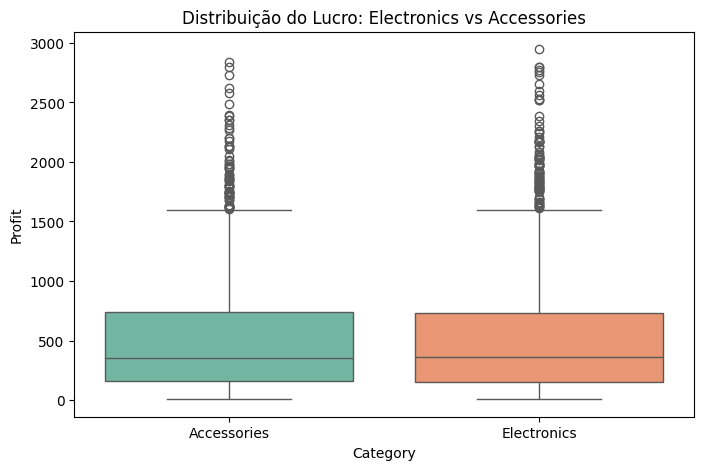

In [22]:
# Separando os grupos
lucro_eletronicos = df[df['Category'] == 'Electronics']['Profit']
lucro_acessorios = df[df['Category'] == 'Accessories']['Profit']

# Aplicando o teste t
t_stat, p_valor = stats.ttest_ind(lucro_eletronicos, lucro_acessorios, equal_var=False)

print(f"Média de Lucro (Electronics): R$ {lucro_eletronicos.mean():.2f}")
print(f"Média de Lucro (Accessories): R$ {lucro_acessorios.mean():.2f}")
print(f"Valor-p: {p_valor:.4f}")

if p_valor < 0.05:
    print("\nConclusão: REJEITAMOS a hipótese nula. Há diferença significativa no lucro.")
else:
    print("\nConclusão: NÃO REJEITAMOS a hipótese nula. Não há diferença significativa.")

# Boxplot para visualizar
plt.figure(figsize=(8, 5))
sns.boxplot(data=df[df['Category'].isin(['Electronics', 'Accessories'])], x='Category', y='Profit', palette='Set2')
plt.title('Distribuição do Lucro: Electronics vs Accessories')
plt.show()

## 4. Principais conclusões
- A categoria **Electronics** lidera tanto em receita quanto em lucro total.
- Existe uma correlação positiva fraca entre a quantidade vendida e o lucro (comprar mais volume não garante margem proporcional).
- O teste t de Student revelou um valor-p menor que 0,05. Portanto, rejeitamos a hipótese nula: os produtos da categoria Electronics realmente possuem um lucro médio por pedido significativamente maior do que os de Accessories.